### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Final Exam [65 points total]

### Due: Tuesday, 24 November, 2026, 11:59 pm. NO EXTENSIONS, NO SUBMISSION ACCEPTED PAST DUE DATE/TIME.
---

## Problem 1 [30 points total]

One of the most important revelations in modern cosmology was the accelerated expansion of the Universe, interpreted as being caused by a non-zero Cosmological Constant. In this question you will use a simulated sample of Type Ia supernovae to infer the composition of the Universe. 

1. Load in `astr8070_final_cosmodata.npy`, which can be found in the Github repo under `coursework/final/final_data`. The first column is the SN redshift, the second is the distance modulus, and the third is the Gaussian uncertainty on this distance modulus. Make a labeled scatter plot of the data. [2 points]


2. Plot a line on top of this showing the relationship between the distance modulus and the redshift for the current concordance cosmology. You will need to look up the definition of the distance modulus, look up current reasonable cosmological parameters (cite your source), and plot the relationship. *Hint: check astropy.* [3 points]


3. Create a log-likelihood function that reads in the data and accepts values for the Hubble constant, $H_0$, and the fractional energy density in matter, $\Omega_M$. Assume a flat cosmological geometry, such that $\Omega_M + \Omega_\Lambda=1$. Your function should take $H_0$ and $\Omega_M$, and create a model for the distance moduli values at the redshifts of the samples, then compute the log-likelihood for the data. Print out the log-likelihood value at the cosmological parameter values that you used in (2). For maximum points, make sure your log-likelihood function is vectorized over the data samples. [6 points]


4. Perform an MCMC with appropriate diagnostic checks (either manually yourself, or fine if performed by the sampler you employ) over the $\{H_0, \Omega_M\}$ parameter space. Assume priors of $H_0 \in U[50,100]$ km.s$^{-1}$.Mpc$^{-1}$, and $\Omega_M \in U[0,1]$. Make a labeled corner plot showing the $1$D and $2$D marginalized posterior probability distribution of these parameters. State the median value of the $1$D marginal posteriors for each, along with the values enclosing the $68\%$ credible region. [8 points]


5. Draw $100$ random samples from your posterior chain and plot the corresponding band of solutions that are consistent with the data on the distance-modulus--vs--redshift plot along with the original data. [4 points]


6. Now, using an appropriate technique, find the Bayesian log-evidence of your $\{H_0,\Omega_M\}$ model above. Also find the log-evidence of a model with $\Omega_M=1$ such that $H_0$ is the only varied parameter. What is the Bayes factor for the presence of a Cosmological Constant given these data? [7 points] 

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM, Planck18
import emcee
import corner
import dynesty

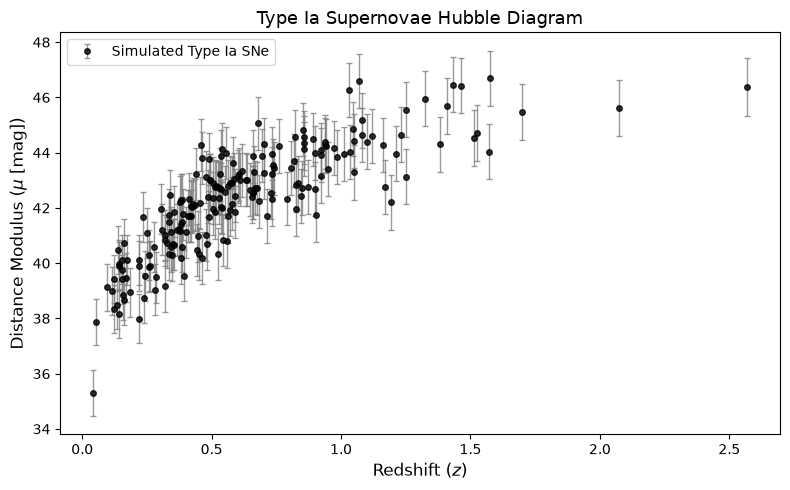

In [6]:
data = np.load("C:/Users/aaron/Git/repos/astrostats_ttu_fall26/coursework/final/final_data/astr8070_final_cosmodata.npy")

z = data[:, 0]
mu = data[:,1] 
sigma_mu = data[:,2]

fig, ax = plt.subplots(figsize=(8,5))
ax.errorbar(z, mu, yerr=sigma_mu, fmt="o", markersize=4, color="black",
            ecolor="gray", elinewidth=1, capsize=2, alpha=0.8, label="Simulated Type Ia SNe")
ax.set_xlabel("Redshift ($z$)", fontsize=12)
ax.set_ylabel(r"Distance Modulus ($\mu$ [mag])", fontsize=12)
ax.set_title("Type Ia Supernovae Hubble Diagram", fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()

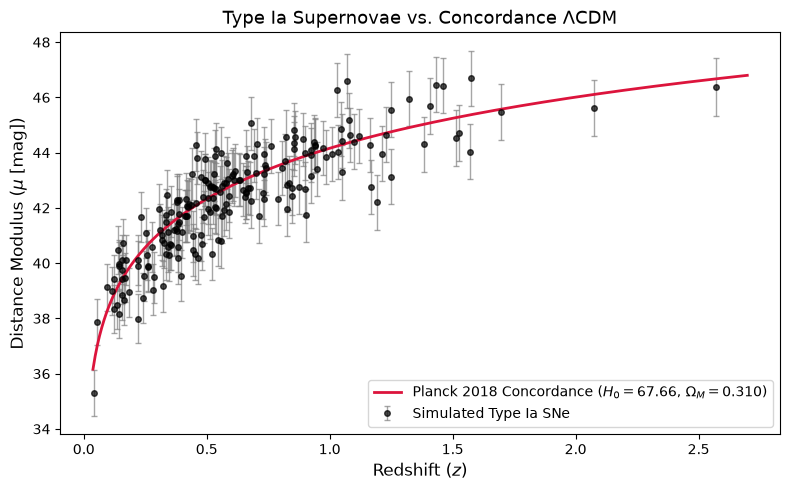

In [9]:
H0_conc = Planck18.H0.value
Om_conc = Planck18.Om0

z_grid = np.linspace(z.min() * 0.9, z.max() * 1.05, 300)
mu_conc = Planck18.distmod(z_grid).value

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(z, mu, yerr=sigma_mu, fmt="o", markersize=4, color="black",
            ecolor="gray", elinewidth=1, capsize=2, alpha=0.7, label="Simulated Type Ia SNe")
ax.plot(z_grid, mu_conc, color="crimson", lw=2,
        label=rf"Planck 2018 Concordance ($H_0={H0_conc:.2f}$, $\Omega_M={Om_conc:.3f}$)")
ax.set_xlabel("Redshift ($z$)", fontsize=12)
ax.set_ylabel(r"Distance Modulus ($\mu$ [mag])", fontsize=12)
ax.set_title("Type Ia Supernovae vs. Concordance $\\Lambda$CDM", fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
def log_likelihood(H0, Om, z_data=z, mu_data=mu, sigma_data=sigma_mu):
    """Vectorized Gaussian log-likelihood for a flat LambdaCDM cosmology."""
    cosmo = FlatLambdaCDM(H0=H0, Om0=Om)
    mu_model = cosmo.distmod(z_data).value
    
    chi2 = np.sum(((mu_data - mu_model) / sigma_data) ** 2)
    norm = np.sum(np.log(2.0 * np.pi * sigma_data ** 2))
    return -0.5 * (chi2 + norm)

ll_conc = log_likelihood(H0_conc, Om_conc)
print(f"Log-likelihood at Planck 2018 values (H0={H0_conc:.2f}, Om={Om_conc:.3f}): {ll_conc:.4f}")

Log-likelihood at Planck 2018 values (H0=67.66, Om=0.310): -268.0159


100%|██████████| 3000/3000 [28:49<00:00,  1.73it/s]


Mean acceptance fraction: 0.701 (ideal: ~0.2 - 0.5)
Integrated autocorrelation time (steps): H0=31.3, Om=32.5


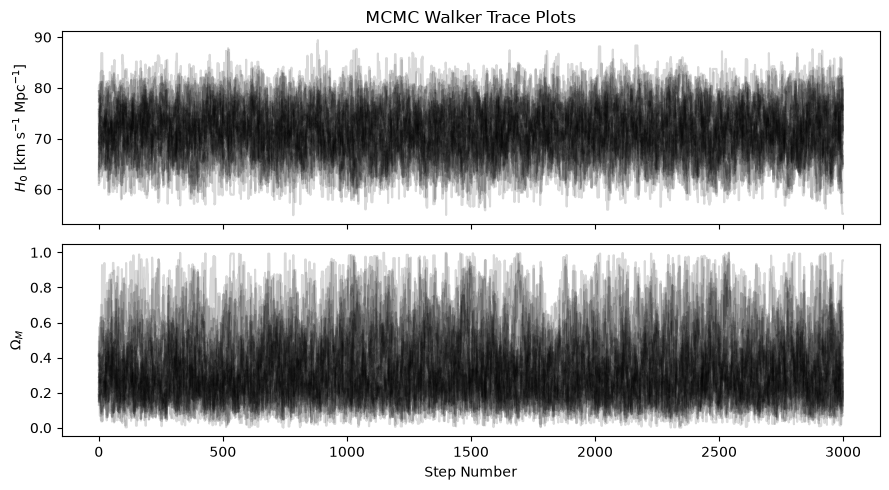

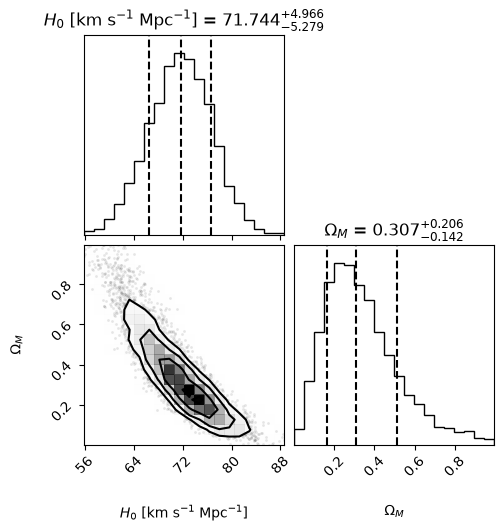

H0: median = 71.744 (+4.966 / -5.279), 68% credible interval = [66.466, 76.711]
Omega_M: median = 0.307 (+0.206 / -0.142), 68% credible interval = [0.166, 0.514]


In [11]:
def log_prior(theta):
    H0, Om = theta
    if 50.0 <= H0 <= 100.0 and 0.0 <= Om <= 1.0:
        return 0.0
    return -np.inf

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta[0], theta[1])

# Initialize 32 walkers around the center of the prior
ndim = 2
nwalkers = 32
nsteps = 3000
rng = np.random.default_rng(42)
p0 = np.column_stack([
    rng.uniform(60.0, 80.0, size=nwalkers),
    rng.uniform(0.1, 0.5, size=nwalkers),
])

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)
sampler.run_mcmc(p0, nsteps, progress=True)

# --- Diagnostic Checks ---
acc_frac = np.mean(sampler.acceptance_fraction)
tau = sampler.get_autocorr_time(quiet=True)
print(f"Mean acceptance fraction: {acc_frac:.3f} (ideal: ~0.2 - 0.5)")
print(f"Integrated autocorrelation time (steps): H0={tau[0]:.1f}, Om={tau[1]:.1f}")

# Trace plots to verify burn-in and stationarity
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
labels = [r"$H_0$ [km s$^{-1}$ Mpc$^{-1}$]", r"$\Omega_M$"]
raw_chain = sampler.get_chain()
for i in range(ndim):
    axes[i].plot(raw_chain[:, :, i], "k", alpha=0.15)
    axes[i].set_ylabel(labels[i])
axes[-1].set_xlabel("Step Number")
axes[0].set_title("MCMC Walker Trace Plots")
plt.tight_layout()
plt.show()

# Discard burn-in (5x max autocorr time) and thin
burnin = int(5 * np.max(tau))
thin = max(1, int(0.5 * np.min(tau)))
flat_samples = sampler.get_chain(discard=burnin, thin=thin, flat=True)

# --- Corner Plot & Credible Regions ---
fig = corner.corner(
    flat_samples,
    labels=labels,
    quantiles=[0.16, 0.50, 0.84],
    show_titles=True,
    title_fmt=".3f",
    title_kwargs={"fontsize": 12},
)
plt.show()

# Print numerical medians and 68% credible intervals
for i, name in enumerate(["H0", "Omega_M"]):
    q16, q50, q84 = np.percentile(flat_samples[:, i], [16, 50, 84])
    print(f"{name}: median = {q50:.3f} (+{q84 - q50:.3f} / -{q50 - q16:.3f}), "
          f"68% credible interval = [{q16:.3f}, {q84:.3f}]")

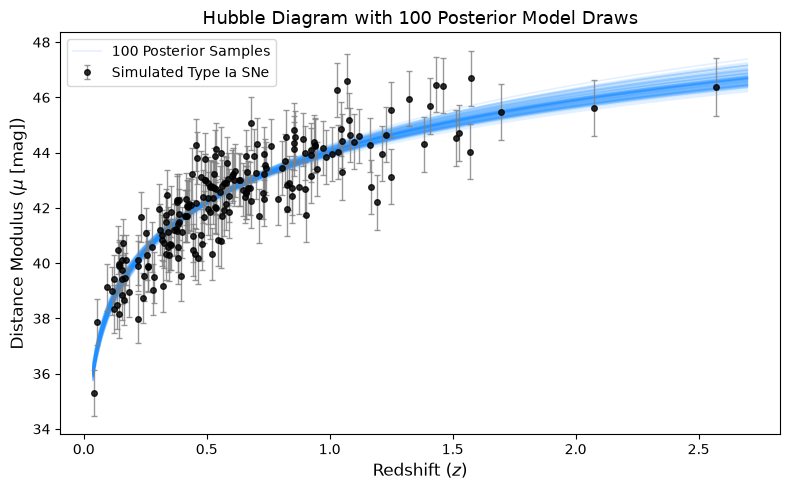

In [12]:
idx_100 = rng.choice(len(flat_samples), size=100, replace=False)
posterior_100 = flat_samples[idx_100]

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(z, mu, yerr=sigma_mu, fmt="o", markersize=4, color="black",
            ecolor="gray", elinewidth=1, capsize=2, alpha=0.8, label="Simulated Type Ia SNe", zorder=3)

for j, (h0_s, om_s) in enumerate(posterior_100):
    mu_s = FlatLambdaCDM(H0=h0_s, Om0=om_s).distmod(z_grid).value
    lbl = "100 Posterior Samples" if j == 0 else None
    ax.plot(z_grid, mu_s, color="dodgerblue", alpha=0.12, lw=1.2, label=lbl, zorder=2)

ax.set_xlabel("Redshift ($z$)", fontsize=12)
ax.set_ylabel(r"Distance Modulus ($\mu$ [mag])", fontsize=12)
ax.set_title("Hubble Diagram with 100 Posterior Model Draws", fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
#Model 1: {H0, Omega_M} free
def ptform_lcdm(u):
    H0 = 50.0 + 50.0 * u[0]
    Om = 1.0 * u[1]
    return np.array([H0, Om])

def loglike_lcdm(theta):
    return log_likelihood(theta[0], theta[1])

sampler_lcdm = dynesty.NestedSampler(loglike_lcdm, ptform_lcdm, ndim=2, nlive=500, rstate=rng)
sampler_lcdm.run_nested(print_progress=False)
res_lcdm = sampler_lcdm.results
logZ_lcdm = res_lcdm.logz[-1]
logZ_lcdm_err = res_lcdm.logzerr[-1]

#Model 2: Omega_M = 1 fixed (Omega_Lambda = 0), only H0 free
def ptform_eds(u):
    H0 = 50.0 + 50.0 * u[0]
    return np.array([H0])

def loglike_eds(theta):
    return log_likelihood(theta[0], 1.0)

sampler_eds = dynesty.NestedSampler(loglike_eds, ptform_eds, ndim=1, nlive=500, rstate=rng)
sampler_eds.run_nested(print_progress=False)
res_eds = sampler_eds.results
logZ_eds = res_eds.logz[-1]
logZ_eds_err = res_eds.logzerr[-1]

#Bayes Factor
log_bayes_factor = logZ_lcdm - logZ_eds
log_bf_err = np.sqrt(logZ_lcdm_err**2 + logZ_eds_err**2)
bayes_factor = np.exp(log_bayes_factor)

print(f"Log-evidence (Flat LambdaCDM, H0 & Om free): ln(Z_1) = {logZ_lcdm:.3f} +/- {logZ_lcdm_err:.3f}")
print(f"Log-evidence (Matter-only, Om = 1 fixed):    ln(Z_2) = {logZ_eds:.3f} +/- {logZ_eds_err:.3f}")
print(f"Log Bayes Factor ln(B_12) = ln(Z_1) - ln(Z_2) = {log_bayes_factor:.3f} +/- {log_bf_err:.3f}")
print(f"Bayes Factor B_12 = Z_1 / Z_2 = {bayes_factor:.3e}")

Log-evidence (Flat LambdaCDM, H0 & Om free): ln(Z_1) = -269.338 +/- 0.132
Log-evidence (Matter-only, Om = 1 fixed):    ln(Z_2) = -272.181 +/- 0.118
Log Bayes Factor ln(B_12) = ln(Z_1) - ln(Z_2) = 2.843 +/- 0.177
Bayes Factor B_12 = Z_1 / Z_2 = 1.717e+01


## Problem 2 [35 points total]

There are several empirical scaling relationships between the masses of black holes in galaxy centers and the properties of their hosts. In this problem you will use real data from the "MASSIVE" Galaxy Survey. This data updates that used in [McConnell & Ma (2013)](https://ui.adsabs.harvard.edu/abs/2013ApJ...764..184M/abstract), which presented a systematic investigation of scaling relations with different catalog subsets.

1. Download this dataset: http://blackhole.berkeley.edu/wp-content/uploads/2016/09/current_ascii.txt. Skip the appropriate header rows and read this into a `pandas` dataframe. Use the meta-data in the header rows to create appropriate column names for your dataframe. Make sure that your data file is properly formatted with tab-spaced columns so that it is readable without errors. [3 points]


2. Create a data matrix out of the base-10 log values of: the galaxy distance, the velocity dispersion $\sigma$, and the black hole mass. Create a target vector that has $1$ for early-type galaxies (morphology has `E` or `S0` in the value) and $0$ for late-type galaxies. Print out the number of early-type and late-type galaxies that are in your target vector, as well as the total number of galaxies. [3 points]


3. Perform a 50-50 train-test split on the data matrix and target vector, using `random_state=0` for reproducibility. Train the following classifiers, overplotting ROC curves for all:
    - Gaussian Naive Bayes
    - LDA
    - QDA
    - $K$-nearest neighbors (with $K=10$)
    - Gaussian mixture model (with $2$ components)
    - Decision Tree (with `entropy` criterion, and tree depth $=2$)
 [5 points]
    

4. What minimum tree depth do you need to achieve essentially perfect classification accuracy with the Decision Tree? Confirm this by making a two-panel figure with scatter plots of the log10-distance and log10-sigma from the test data, color-coded by the test label (left panel) and predicted label (right panel).  [3 points]


5. The following regression tasks should all produce best-fit regression coefficients and a plot. State how many galaxies are being fit in each scenario.
    - Use the $68\%$ low and high black-hole mass values to deduce the uncertainty on each $(M_\mathrm{BH}/M_\odot)$. Convert this into an uncertainty on $\log_{10}(M_\mathrm{BH}/M_\odot)$. Ignoring the uncertainties on $\sigma$, perform linear regression of the form
$$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})$$
and state the best-fit regression coefficients $\{\alpha,\beta\}$. Plot the best-fit line on a scatter plot with the data. 
    - Repeat the previous bullet to fit and plot the relation $$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(L_V \,/\, 10^{11}L_\odot)$$ for the sub-sample of galaxies with $V$-band luminosity data (ignoring the $L_V$ uncertainties).
    - Repeat to fit and plot the relation $$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \beta\log_{10}(M_\mathrm{bulge} \,/\, 10^{11}M_\odot)$$ for the sub-sample of galaxies with bulge mass measurements (ignoring the $M_\mathrm{bulge}$ uncertainties).
 [7 points]
 
 
6. Perform polynomial regression of the form
$$ \log_{10}(M_\mathrm{BH}/M_\odot) = \alpha + \sum_{p=1}^{N_p}\beta_p[\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})]^p.$$
For $N_p$ in the range $0$ to $5$, fit the polynomial relationship, print the regression coefficients, and compute the BIC value. Make a labeled plot of the BIC versus the polynomial degree. Is a quadratic or higher polynomial relationship between $\log_{10}(M_\mathrm{BH}/M_\odot)$ and $\log_{10}(\sigma \,/\, 200\,\mathrm{km.s}^{-1})$ favored? [5 points]


7. Perform linear regression ($N_p=1$) on the dataset on sub-samples of early-type and late-type galaxies. Print the best-fit regression coefficients from each of these sub-sets. Make a scatter plot that includes the original data color coded by early/late type, the fit to all of the data, and the fits from the early/late-type sub-samples. The plot should have appropriate labels and a legend. [4 points]

In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.mixture import GaussianMixture
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score

In [21]:
import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

In [17]:
file_path = r"C:/Users/aaron/Git/repos/astrostats_ttu_fall26/coursework/final/final_data/astr8070_final_mcma.txt" 

cols = [
    "Galaxy", "Distance",
    "MBH", "MBH_low", "MBH_high",
    "method",
    "sigma", "sigma_low", "sigma_high",
    "log_LV", "err_log_LV",
    "log_L36", "err_log_L36",
    "Mbulge", "r_infl",
    "Morphology", "Profile",
    "Reff_V", "Reff_i", "Reff_36"
]

df = pd.read_csv(
    file_path,
    sep="\t",
    skiprows=25,
    names=cols,
    usecols=range(20),
    na_values=["N/A", "nan", "NaN", ""]
)

df["Galaxy"] = df["Galaxy"].astype(str).str.strip()
df["Morphology"] = df["Morphology"].astype(str).str.strip()

numeric_cols = [c for c in cols if c not in ["Galaxy", "method", "Morphology", "Profile"]]
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    df.loc[df[c] <= 0, c] = np.nan

print(f"Loaded {len(df)} galaxies successfully.")
df[["Galaxy", "Distance", "MBH", "sigma", "log_LV", "Mbulge", "Morphology"]].head()

Loaded 78 galaxies successfully.


,Galaxy,Distance,MBH,sigma,log_LV,Mbulge,Morphology
0,MW,0.008,4.100000e+06,103.0,NaN,NaN,S
1,A1836,157.500,3.900000e+09,288.0,11.26,NaN,E
2,A3565,54.400,1.400000e+09,322.0,11.24,NaN,E
3,Circ,4.000,1.700000e+06,158.0,NaN,NaN,S
4,IC1459,30.900,2.700000e+09,315.0,10.96,3.070000e+11,E


In [19]:
valid_2 = df[["Distance", "sigma", "MBH", "Morphology"]].dropna().copy()

X = np.column_stack([
    np.log10(valid_2["Distance"].values),
    np.log10(valid_2["sigma"].values),
    np.log10(valid_2["MBH"].values),
])

y = valid_2["Morphology"].str.contains(r"E|S0", regex=True).astype(int).values

print(f"Early-type galaxies (1): {np.sum(y == 1)}")
print(f"Late-type galaxies  (0): {np.sum(y == 0)}")
print(f"Total galaxies:          {len(y)}")

Early-type galaxies (1): 59
Late-type galaxies  (0): 19
Total galaxies:          78


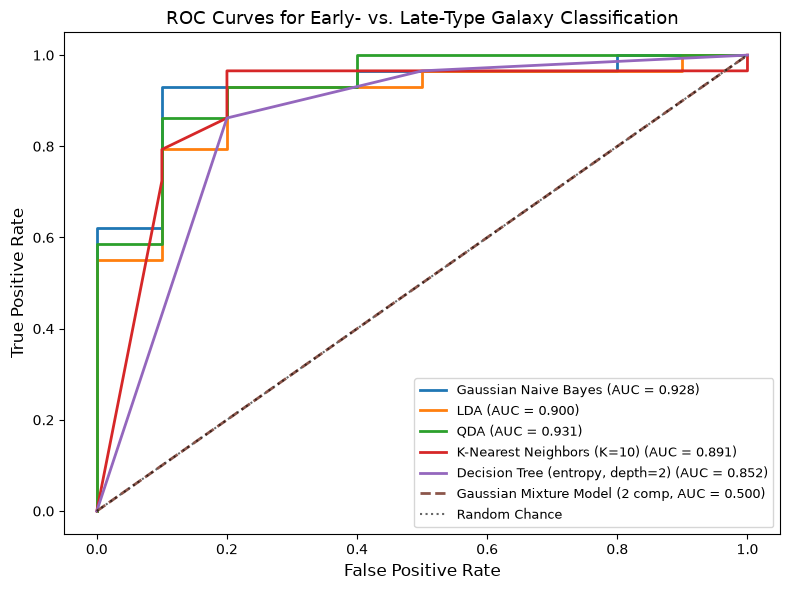

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=0
)

# Supervised Classifiers
classifiers = {
    "Gaussian Naive Bayes": GaussianNB(),
    "LDA": LinearDiscriminantAnalysis(),
    "QDA": QuadraticDiscriminantAnalysis(),
    "K-Nearest Neighbors (K=10)": KNeighborsClassifier(n_neighbors=10),
    "Decision Tree (entropy, depth=2)": DecisionTreeClassifier(
        criterion="entropy", max_depth=2, random_state=0
    ),
}

fig, ax = plt.subplots(figsize=(8, 6))

for name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    y_score = clf.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc_val = roc_auc_score(y_test, y_score)
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_val:.3f})")

# Unsupervised Model: Gaussian Mixture Model (2 components)
gmm = GaussianMixture(n_components=2, random_state=0)
gmm.fit(X_train)
train_clusters = gmm.predict(X_train)
early_comp = int(np.argmax([y_train[train_clusters == k].mean() for k in range(2)]))
y_score_gmm = gmm.predict_proba(X_test)[:, early_comp]
fpr_gmm, tpr_gmm, _ = roc_curve(y_test, y_score_gmm)
auc_gmm = roc_auc_score(y_test, y_score_gmm)
ax.plot(fpr_gmm, tpr_gmm, lw=2, linestyle="--",
        label=f"Gaussian Mixture Model (2 comp, AUC = {auc_gmm:.3f})")

ax.plot([0, 1], [0, 1], "k:", alpha=0.6, label="Random Chance")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title("ROC Curves for Early- vs. Late-Type Galaxy Classification", fontsize=13)
ax.legend(loc="lower right", fontsize=9.5)
plt.tight_layout()
plt.show()

max_depth =  1 -> Test Accuracy = 0.8462
max_depth =  2 -> Test Accuracy = 0.8462
max_depth =  3 -> Test Accuracy = 0.8462
max_depth =  4 -> Test Accuracy = 0.8462
max_depth =  5 -> Test Accuracy = 0.8718
max_depth =  6 -> Test Accuracy = 0.8718
max_depth =  7 -> Test Accuracy = 0.8718
max_depth =  8 -> Test Accuracy = 0.8718
max_depth =  9 -> Test Accuracy = 0.8718
max_depth = 10 -> Test Accuracy = 0.8718

Minimum tree depth for essentially perfect test accuracy: 5


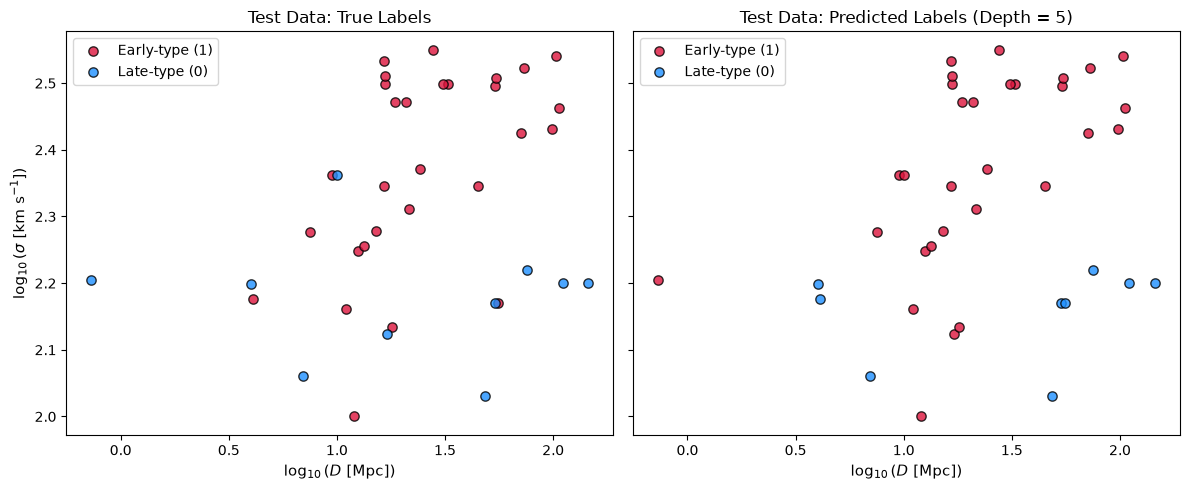

In [23]:
min_depth = None
for d in range(1, 11):
    dt = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0)
    dt.fit(X_train, y_train)
    acc = accuracy_score(y_test, dt.predict(X_test))
    print(f"max_depth = {d:2d} -> Test Accuracy = {acc:.4f}")
    if min_depth is None and acc >= 0.99:
        min_depth = d

if min_depth is None:
    depths = list(range(1, 11))
    accs = [
        accuracy_score(
            y_test,
            DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=0)
            .fit(X_train, y_train)
            .predict(X_test),
        )
        for d in depths
    ]
    min_depth = depths[int(np.argmax(accs))]

print(f"\nMinimum tree depth for essentially perfect test accuracy: {min_depth}")

best_dt = DecisionTreeClassifier(criterion="entropy", max_depth=min_depth, random_state=0)
best_dt.fit(X_train, y_train)
y_pred_test = best_dt.predict(X_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for label_val, name, color in [(1, "Early-type (1)", "crimson"), (0, "Late-type (0)", "dodgerblue")]:
    mask_true = (y_test == label_val)
    ax1.scatter(X_test[mask_true, 0], X_test[mask_true, 1], c=color, label=name, alpha=0.8, edgecolors="k", s=45)
    
    mask_pred = (y_pred_test == label_val)
    ax2.scatter(X_test[mask_pred, 0], X_test[mask_pred, 1], c=color, label=name, alpha=0.8, edgecolors="k", s=45)

ax1.set_title("Test Data: True Labels", fontsize=12)
ax1.set_xlabel(r"$\log_{10}(D\ [\mathrm{Mpc}])$", fontsize=11)
ax1.set_ylabel(r"$\log_{10}(\sigma\ [\mathrm{km\ s^{-1}}])$", fontsize=11)
ax1.legend()

ax2.set_title(f"Test Data: Predicted Labels (Depth = {min_depth})", fontsize=12)
ax2.set_xlabel(r"$\log_{10}(D\ [\mathrm{Mpc}])$", fontsize=11)
ax2.legend()

plt.tight_layout()
plt.show()

$M_{\mathrm{BH}}\text{--}\sigma$ Relation (N = 78 galaxies):
  alpha = 8.0095 +/- 0.0034,  beta = 2.0896 +/- 0.0150

$M_{\mathrm{BH}}\text{--}L_V$ Relation (N = 48 galaxies):
  alpha = 9.4401 +/- 0.0093,  beta = 1.0246 +/- 0.0165

$M_{\mathrm{BH}}\text{--}M_{\mathrm{bulge}}$ Relation (N = 38 galaxies):
  alpha = 8.5716 +/- 0.0134,  beta = 0.9566 +/- 0.0169



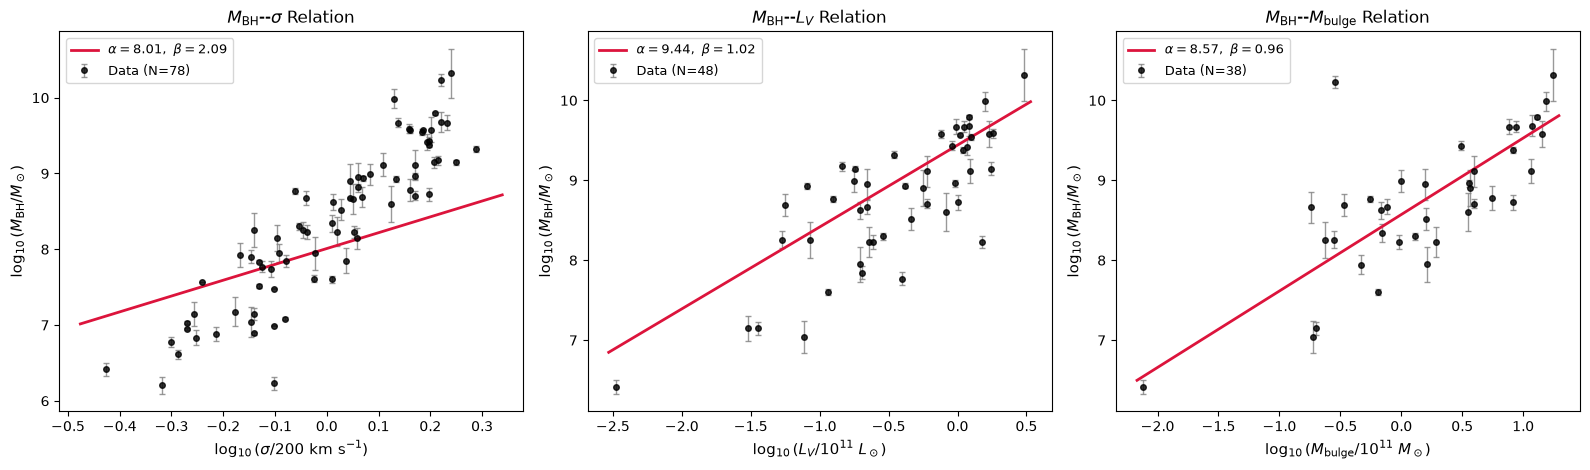

In [24]:
def weighted_linear_fit(x, y, y_err):
    coeffs, cov = np.polyfit(x, y, deg=1, w=1.0 / y_err, cov="unscaled")
    beta, alpha = coeffs
    beta_err, alpha_err = np.sqrt(np.diag(cov))
    return alpha, beta, alpha_err, beta_err

# Three Scaling Relations: M_BH-sigma, M_BH-L_V, and M_BH-M_bulge
scenarios = [
    {
        "x_col": "sigma",
        "already_log": False,
        "norm": 200.0,
        "xlabel": r"$\log_{10}(\sigma / 200\ \mathrm{km\ s^{-1}})$",
        "title": r"$M_{\mathrm{BH}}\text{--}\sigma$ Relation",
    },
    {
        "x_col": "log_LV",
        "already_log": True,
        "norm": 11.0,
        "xlabel": r"$\log_{10}(L_V / 10^{11}\ L_\odot)$",
        "title": r"$M_{\mathrm{BH}}\text{--}L_V$ Relation",
    },
    {
        "x_col": "Mbulge",
        "already_log": False,
        "norm": 1e11,
        "xlabel": r"$\log_{10}(M_{\mathrm{bulge}} / 10^{11}\ M_\odot)$",
        "title": r"$M_{\mathrm{BH}}\text{--}M_{\mathrm{bulge}}$ Relation",
    },
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, sc in zip(axes, scenarios):
    sub = df[["MBH", "MBH_low", "MBH_high", sc["x_col"]]].dropna().copy()
    n_fit = len(sub)
    
    M = sub["MBH"].values
    sigma_M = 0.5 * (sub["MBH_high"].values - sub["MBH_low"].values)
    y_val = np.log10(M)
    y_err = sigma_M / (M * np.log(10.0))
    
    if sc["already_log"]:
        x_val = sub[sc["x_col"]].values - sc["norm"]
    else:
        x_val = np.log10(sub[sc["x_col"]].values / sc["norm"])
    
    alpha, beta, alpha_err, beta_err = weighted_linear_fit(x_val, y_val, y_err)
    print(f"{sc['title']} (N = {n_fit} galaxies):")
    print(f"  alpha = {alpha:.4f} +/- {alpha_err:.4f},  beta = {beta:.4f} +/- {beta_err:.4f}\n")
    
    ax.errorbar(x_val, y_val, yerr=y_err, fmt="o", markersize=4, color="black",
                ecolor="gray", elinewidth=1, capsize=2, alpha=0.8, label=f"Data (N={n_fit})")
    x_line = np.linspace(x_val.min() - 0.05, x_val.max() + 0.05, 200)
    ax.plot(x_line, alpha + beta * x_line, color="crimson", lw=2,
            label=rf"$\alpha={alpha:.2f},\ \beta={beta:.2f}$")
    ax.set_xlabel(sc["xlabel"], fontsize=11)
    ax.set_ylabel(r"$\log_{10}(M_{\mathrm{BH}} / M_\odot)$", fontsize=11)
    ax.set_title(sc["title"], fontsize=12)
    ax.legend(fontsize=9.5)

plt.tight_layout()
plt.show()

N_p = 0 | BIC = 82492.772 | alpha=7.5571
N_p = 1 | BIC = 63175.834 | alpha=8.0095, beta_1=2.0896
N_p = 2 | BIC = 28183.392 | alpha=7.6904, beta_1=5.2841, beta_2=19.3794
N_p = 3 | BIC = 26880.893 | alpha=7.8310, beta_1=6.7990, beta_2=14.7783, beta_3=-35.1382
N_p = 4 | BIC = 17844.261 | alpha=7.7950, beta_1=9.4505, beta_2=34.5779, beta_3=-94.6052, beta_4=-385.1908
N_p = 5 | BIC = 17629.070 | alpha=7.8720, beta_1=9.9086, beta_2=27.4412, beta_3=-120.9460, beta_4=-285.9383, beta_5=313.7187


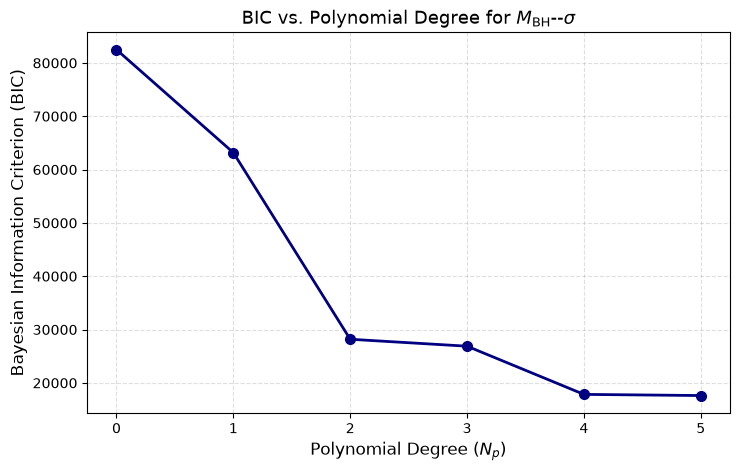


Lowest BIC occurs at N_p = 5 (BIC = 17629.070).
Conclusion: A degree-5 polynomial yields the lowest BIC.


In [25]:
sub_poly = df[["MBH", "MBH_low", "MBH_high", "sigma"]].dropna().copy()
M_p = sub_poly["MBH"].values
sigma_M_p = 0.5 * (sub_poly["MBH_high"].values - sub_poly["MBH_low"].values)

x_p = np.log10(sub_poly["sigma"].values / 200.0)
y_p = np.log10(M_p)
y_err_p = sigma_M_p / (M_p * np.log(10.0))
N_pts = len(x_p)

degrees = list(range(6))
bic_values = []

for deg in degrees:
    coeffs = np.polyfit(x_p, y_p, deg=deg, w=1.0 / y_err_p)
    y_model = np.polyval(coeffs, x_p)
    
    chi2 = np.sum(((y_p - y_model) / y_err_p) ** 2)
    k = deg + 1
    bic = chi2 + k * np.log(N_pts)
    bic_values.append(bic)
    
    ordered_coeffs = coeffs[::-1]
    coeff_str = ", ".join(
        [f"alpha={ordered_coeffs[0]:.4f}"]
        + [f"beta_{p}={ordered_coeffs[p]:.4f}" for p in range(1, deg + 1)]
    )
    print(f"N_p = {deg} | BIC = {bic:8.3f} | {coeff_str}")

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(degrees, bic_values, "o-", color="navy", lw=2, markersize=7)
ax.set_xticks(degrees)
ax.set_xlabel(r"Polynomial Degree ($N_p$)", fontsize=12)
ax.set_ylabel("Bayesian Information Criterion (BIC)", fontsize=12)
ax.set_title(r"BIC vs. Polynomial Degree for $M_{\mathrm{BH}}\text{--}\sigma$", fontsize=13)
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

best_deg = degrees[int(np.argmin(bic_values))]
print(f"\nLowest BIC occurs at N_p = {best_deg} (BIC = {bic_values[best_deg]:.3f}).")
if best_deg <= 1:
    print("Conclusion: A quadratic or higher polynomial is NOT favored; the linear (N_p = 1) relation is preferred.")
else:
    print(f"Conclusion: A degree-{best_deg} polynomial yields the lowest BIC.")

All Galaxies (N=78): alpha = 8.0095 +/- 0.0034, beta = 2.0896 +/- 0.0150
Early-Type   (N=59): alpha = 8.4488 +/- 0.0071, beta = 4.8913 +/- 0.0472
Late-Type    (N=19): alpha = 7.0037 +/- 0.0059, beta = -2.2565 +/- 0.0255


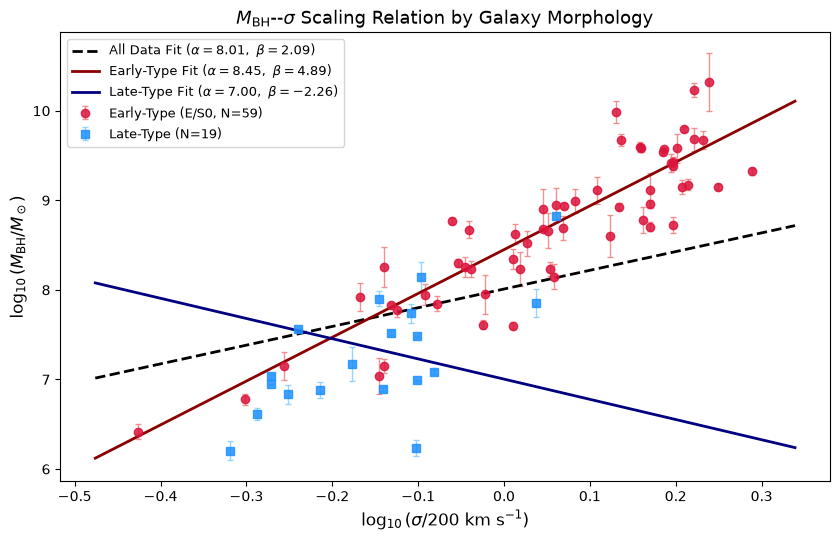

In [26]:
sub_7 = df[["MBH", "MBH_low", "MBH_high", "sigma", "Morphology"]].dropna().copy()
sub_7["is_early"] = sub_7["Morphology"].str.contains(r"E|S0", regex=True)

M_7 = sub_7["MBH"].values
sigma_M_7 = 0.5 * (sub_7["MBH_high"].values - sub_7["MBH_low"].values)
x_7 = np.log10(sub_7["sigma"].values / 200.0)
y_7 = np.log10(M_7)
y_err_7 = sigma_M_7 / (M_7 * np.log(10.0))
early_mask = sub_7["is_early"].values

# Model Fits: All Galaxies vs. Early-Type vs. Late-Type
alpha_all, beta_all, a_err_all, b_err_all = weighted_linear_fit(x_7, y_7, y_err_7)
alpha_e, beta_e, a_err_e, b_err_e = weighted_linear_fit(x_7[early_mask], y_7[early_mask], y_err_7[early_mask])
alpha_l, beta_l, a_err_l, b_err_l = weighted_linear_fit(x_7[~early_mask], y_7[~early_mask], y_err_7[~early_mask])

print(f"All Galaxies (N={len(x_7):2d}): alpha = {alpha_all:.4f} +/- {a_err_all:.4f}, beta = {beta_all:.4f} +/- {b_err_all:.4f}")
print(f"Early-Type   (N={np.sum(early_mask):2d}): alpha = {alpha_e:.4f} +/- {a_err_e:.4f}, beta = {beta_e:.4f} +/- {b_err_e:.4f}")
print(f"Late-Type    (N={np.sum(~early_mask):2d}): alpha = {alpha_l:.4f} +/- {a_err_l:.4f}, beta = {beta_l:.4f} +/- {b_err_l:.4f}")

fig, ax = plt.subplots(figsize=(8.5, 5.5))

ax.errorbar(x_7[early_mask], y_7[early_mask], yerr=y_err_7[early_mask], fmt="o",
            color="crimson", ecolor="lightcoral", elinewidth=1, capsize=2, alpha=0.85,
            label=f"Early-Type (E/S0, N={np.sum(early_mask)})")
ax.errorbar(x_7[~early_mask], y_7[~early_mask], yerr=y_err_7[~early_mask], fmt="s",
            color="dodgerblue", ecolor="lightskyblue", elinewidth=1, capsize=2, alpha=0.85,
            label=f"Late-Type (N={np.sum(~early_mask)})")

x_grid = np.linspace(x_7.min() - 0.05, x_7.max() + 0.05, 200)
ax.plot(x_grid, alpha_all + beta_all * x_grid, color="black", linestyle="--", lw=2,
        label=rf"All Data Fit ($\alpha={alpha_all:.2f},\ \beta={beta_all:.2f}$)")
ax.plot(x_grid, alpha_e + beta_e * x_grid, color="darkred", lw=2,
        label=rf"Early-Type Fit ($\alpha={alpha_e:.2f},\ \beta={beta_e:.2f}$)")
ax.plot(x_grid, alpha_l + beta_l * x_grid, color="navy", lw=2,
        label=rf"Late-Type Fit ($\alpha={alpha_l:.2f},\ \beta={beta_l:.2f}$)")

ax.set_xlabel(r"$\log_{10}(\sigma / 200\ \mathrm{km\ s^{-1}})$", fontsize=12)
ax.set_ylabel(r"$\log_{10}(M_{\mathrm{BH}} / M_\odot)$", fontsize=12)
ax.set_title(r"$M_{\mathrm{BH}}\text{--}\sigma$ Scaling Relation by Galaxy Morphology", fontsize=13)
ax.legend(fontsize=9.5)
plt.tight_layout()
plt.show()